# Problema 2 - Regressão Logística para Previsão de Doenças Cardíacas

## Pré-processamento dos Dados

In [1]:
import pandas as pd ## Importando a biblioteca Pandas para trabalhar com o DataFrame
import numpy as np ## Importando o NumPy para operações matemáticas
import matplotlib.pyplot as plt ## Importando o matplotlib para plotar o gráfico da Curva ROC
from sklearn.model_selection import train_test_split ## Função para dividir os dados em treino (80%) e teste (20%)
from sklearn.preprocessing import StandardScaler ## Ferramenta para padronizar as 13 variáveis clínicas na mesma escala (Z-score)
from sklearn.linear_model import LogisticRegression ## Modelo de Regressão Logística (apesar do nome 'Regressão', é um modelo de CLASSIFICAÇÃO binária: 0 ou 1)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_curve, roc_auc_score, confusion_matrix
) ## Importando todas as funções de métricas pedidas pelo professor na Tarefa 2

## Carregando o dataset Heart Disease Cleveland
## Detalhe importante do dataset: no arquivo original da UCI, os dados faltantes não estão em branco, eles vêm com um ponto de interrogação '?'
## --> passando o parâmetro na_values='?', avisamos ao Pandas que qualquer '?' deve ser transformado em valor nulo (NaN) de verdade
df = pd.read_csv('heart_cleveland.csv', na_values='?')

print('Total de registros iniciais:', len(df)) ## len(df) mostra a quantidade inicial de tuplas/linhas: 303 pacientes
print('Valores ausentes por coluna:')
print(df.isna().sum()) ## soma os valores nulos de todas as colunas de uma vez: vemos que existem 4 nulos na coluna 'ca' e 2 nulos na coluna 'thal' (total = 6 linhas)

## Removendo as linhas com valores ausentes
df = df.dropna() ## .dropna() apaga do DataFrame as 6 linhas que continham valores nulos, deixando apenas pacientes com todos os exames completos
print('\nTotal de registros apos tratar valores ausentes:', len(df)) ## conferindo que agora temos 297 pacientes (303 - 6 = 297)

## Binarizando a variavel alvo (target) conforme pedido no enunciado:
## No dataset original, target = 0 significa pessoa saudável, e target = 1, 2, 3 ou 4 indicam graus de doença cardíaca.
## O professor pediu para binarizar: 0 (sem doença) e 1 (com doença).
## --> (df['target'] > 0) verifica quem é maior que zero (devolve True para 1, 2, 3, 4 e False para 0)
## --> .astype(int) converte True para 1 e False para 0
df['target'] = (df['target'] > 0).astype(int)
print('\nDistribuicao da variavel target binarizada:')
print(df['target'].value_counts()) ## .value_counts() conta quantos pacientes ficaram na classe 0 (160 saudáveis) e quantos na classe 1 (137 com doença)

## Separando variaveis independentes (X) e variavel dependente alvo (y) - Corte Vertical nas Colunas
X = df.drop('target', axis=1) ## df.drop('target', axis=1) pega a tabela inteira e joga fora apenas a coluna 'target' (axis=1 indica coluna), sobrando as 13 colunas clínicas
y = df['target'] ## guarda em y apenas a coluna alvo binarizada (0 ou 1)

## Dividindo em conjunto de treino (80% = 237 pacientes) e teste (20% = 60 pacientes) - Corte Horizontal nas Linhas
## Lembrando a regra dos pares na sintaxe: 1º par (X_train, X_test) recebe a divisão de X; 2º par (y_train, y_test) recebe a divisão de y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Padronizando as variaveis independentes com StandardScaler (Z-score: média 0 e desvio padrão 1)
## Como temos variáveis que são apenas 0/1 (como sexo) misturadas com variáveis que chegam a 300 (como colesterol 'chol'), precisamos deixar todas na mesma escala
scaler = StandardScaler() ## criando o padronizador
X_train_scaled = scaler.fit_transform(X_train) ## no treino usamos fit_transform (aprende a média/desvio do treino e já padroniza)
X_test_scaled = scaler.transform(X_test) ## no teste usamos apenas transform (usa a média/desvio do treino para não ter vazamento de dados)

Total de registros iniciais: 303
Valores ausentes por coluna:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Total de registros apos tratar valores ausentes: 297

Distribuicao da variavel target binarizada:
target
0    160
1    137
Name: count, dtype: int64


## Tarefa 1: Treinamento do Modelo e Convergência

In [2]:
## Tarefa 1: Treinando a Regressao Logistica exatamente com os 3 parametros exigidos pelo professor no PDF:
## --> solver='liblinear': é o algoritmo matemático interno que resolve a otimização (o 'liblinear' é o mais indicado para bases pequenas e problemas binários 0/1)
## --> random_state=42: trava a semente de aleatoriedade interna do solver para garantir reprodutibilidade
## --> max_iter=1000: define que o algoritmo pode dar no máximo 1000 passos (iterações) tentando achar os pesos ideais antes de desistir
modelo = LogisticRegression(solver='liblinear', random_state=42, max_iter=1000)
modelo.fit(X_train_scaled, y_train) ## .fit() realiza o treinamento cruzando os exames dos 237 pacientes de treino com o diagnóstico real deles

## Verificando quantas iteracoes foram necessarias para a convergencia (pergunta direta da Tarefa 1):
## O que é convergir? É quando os pesos da equação estabilizam e o erro para de cair, ou seja, o modelo terminou de aprender.
## O atributo modelo.n_iter_[0] mostra exatamente quantos passos ele precisou dar: apenas 6 iterações (muito abaixo do limite de 1000!)
print(f'Numero de iteracoes para convergencia: {modelo.n_iter_[0]}')

Numero de iteracoes para convergencia: 6


### Análise da Tarefa 1
- Utilizando os parâmetros `solver='liblinear'`, `random_state=42` e `max_iter=1000` sobre os dados padronizados, o modelo precisou de apenas **6 iterações** para convergir.

## Tarefa 2: Avaliação do Modelo e Curva ROC / AUC

Acuracia: 0.8667
Precisao: 0.8333
Recall:   0.8333
F1-score: 0.8333
ROC AUC:  0.9421

Matriz de Confusao:
[[32  4]
 [ 4 20]]


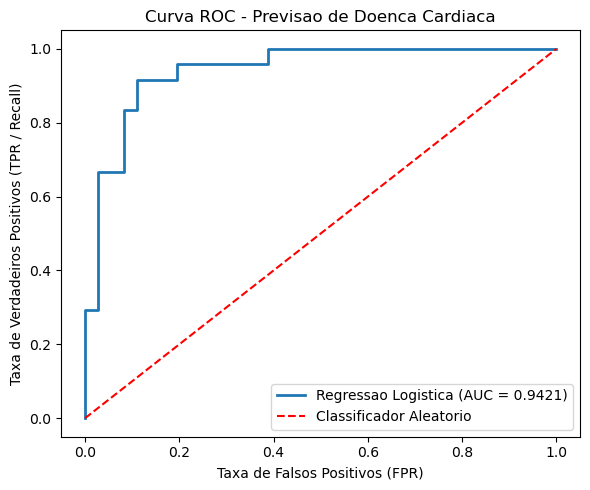

In [3]:
## Tarefa 2: Avaliando o modelo nos 60 pacientes do conjunto de teste
## Aqui tiramos duas coisas do modelo sobre os dados de teste (X_test_scaled):
y_pred = modelo.predict(X_test_scaled)
## --> .predict() devolve a resposta cravada (0 = sem doença, 1 = com doença) usando o corte padrão de 50% (0.5)
y_prob = modelo.predict_proba(X_test_scaled)[:, 1]
## --> .predict_proba() devolve duas colunas: [probabilidade de ser 0, probabilidade de ser 1].
## --> Usando [:, 1], pegamos todas as linhas (:) da coluna 1, que é a probabilidade (de 0% a 100%) de o paciente estar doente. Precisamos disso para traçar a Curva ROC!

## Calculando as 5 metricas solicitadas comparando o gabarito (y_test) com as previsoes do modelo:
acuracia = accuracy_score(y_test, y_pred)
## --> Acurácia (0.8667): de todos os 60 pacientes do teste, o modelo acertou 86,67% no total (52 acertos em 60).
precisao = precision_score(y_test, y_pred)
## --> Precisão (0.8333): olha para os alarmes positivos do modelo. De todos que o modelo falou "está doente", 83,33% realmente estavam doentes.
recall = recall_score(y_test, y_pred)
## --> Recall / Sensibilidade (0.8333): olha para os doentes reais. De todos os pacientes que tinham doença de verdade, o modelo conseguiu capturar 83,33%.
f1 = f1_score(y_test, y_pred)
## --> F1-score (0.8333): é a média harmônica entre Precisão e Recall. Como os dois deram 0.8333, o F1 também deu 0.8333.
auc = roc_auc_score(y_test, y_prob)
## --> AUC (Area Under the Curve = 0.9421): mede a área embaixo da Curva ROC (vai de 0.5 a 1.0). Quanto mais perto de 1.0, melhor o modelo separa saudáveis de doentes.

print(f'Acuracia: {acuracia:.4f}')
print(f'Precisao: {precisao:.4f}')
print(f'Recall:   {recall:.4f}')
print(f'F1-score: {f1:.4f}')
print(f'ROC AUC:  {auc:.4f}')
print('\nMatriz de Confusao:')
print(confusion_matrix(y_test, y_pred))
## Como ler a Matriz de Confusão [[32, 4], [4, 20]] impressa acima:
## --> Linha 0 (Pacientes Saudáveis reais = 36): 32 foram previstos certos como saudáveis (Verdadeiro Negativo) e 4 foram previstos errados como doentes (Falso Positivo).
## --> Linha 1 (Pacientes Doentes reais = 24): 4 passaram batido como saudáveis (Falso Negativo) e 20 foram detectados certos como doentes (Verdadeiro Positivo).

## Plotando a Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
## --> roc_curve testa vários limites de probabilidade e devolve o FPR (Taxa de Falsos Positivos, eixo X) e o TPR (Taxa de Verdadeiros Positivos / Recall, eixo Y)
plt.figure(figsize=(6, 5)) ## reservando o quadro de tamanho 6 por 5
plt.plot(fpr, tpr, label=f'Regressao Logistica (AUC = {auc:.4f})', lw=2) ## desenha a curva azul do nosso modelo (quanto mais ela sobe para o canto superior esquerdo, melhor)
plt.plot([0, 1], [0, 1], 'r--', label='Classificador Aleatorio') ## desenha a linha vermelha tracejada na diagonal, que representa um modelo cego chutando 50/50 (AUC = 0.5)
plt.xlabel('Taxa de Falsos Positivos (FPR)') ## rótulo do eixo X
plt.ylabel('Taxa de Verdadeiros Positivos (TPR / Recall)') ## rótulo do eixo Y
plt.title('Curva ROC - Previsao de Doenca Cardiaca') ## título do gráfico
plt.legend(loc='lower right') ## posiciona a caixinha de legenda no canto inferior direito
plt.tight_layout() ## ajusta as margens
plt.show() ## exibe o gráfico

### Análise da Tarefa 2

**Métricas obtidas no conjunto de teste:**
- **Acurácia:** `0.8667` (86,67% de acertos totais)
- **Precisão:** `0.8333` (dos pacientes classificados como doentes, 83,33% realmente tinham doença cardíaca)
- **Recall (Sensibilidade):** `0.8333` (dos pacientes que realmente tinham a doença, o modelo detectou 83,33%)
- **F1-score:** `0.8333`
- **AUC (Área sob a Curva ROC):** `0.9421`

O valor de **AUC = 0.9421** mostra que o classificador possui excelente capacidade discriminativa entre pacientes com e sem doença cardíaca.